## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### **Latest update**: Oct. 5 / 2026, 5:00 am, Jorge I. Zuluaga

## Seaching for spectra, rotation and orbit

The purpose of this notebook is to search for spectra, rotation and orbit of asteroids in the VRO (Vera C. Rubin Observatory) survey.

> **Attention**: Before running this notebook please get all the required data using the accompanying script `get_data.sh`.

### Tools required

In [ ]:
# !pip install -Uq sorcha layup rebound pymcel pyarrow multimin alerce pyvo scikit-learn gdown
# !gdown 1mAUEoHxpvZk0HqeZe4wgOIcZMi-tYemy # util.py

In [1]:
from util import *
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from astroquery.jplsbdb import SBDB
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle
import re
from scipy.signal import find_peaks

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

# Check that data files exists
get_data()

Data already exists: data/obs_sbn_X05_full.parquet
Data already exists: data/mpcorb_extended.dat.gz
Data already exists: data/asteroids-with-rotation.csv
Data already exists: data/X05_simplified.csv
Download complete or files already present.


### Filter information

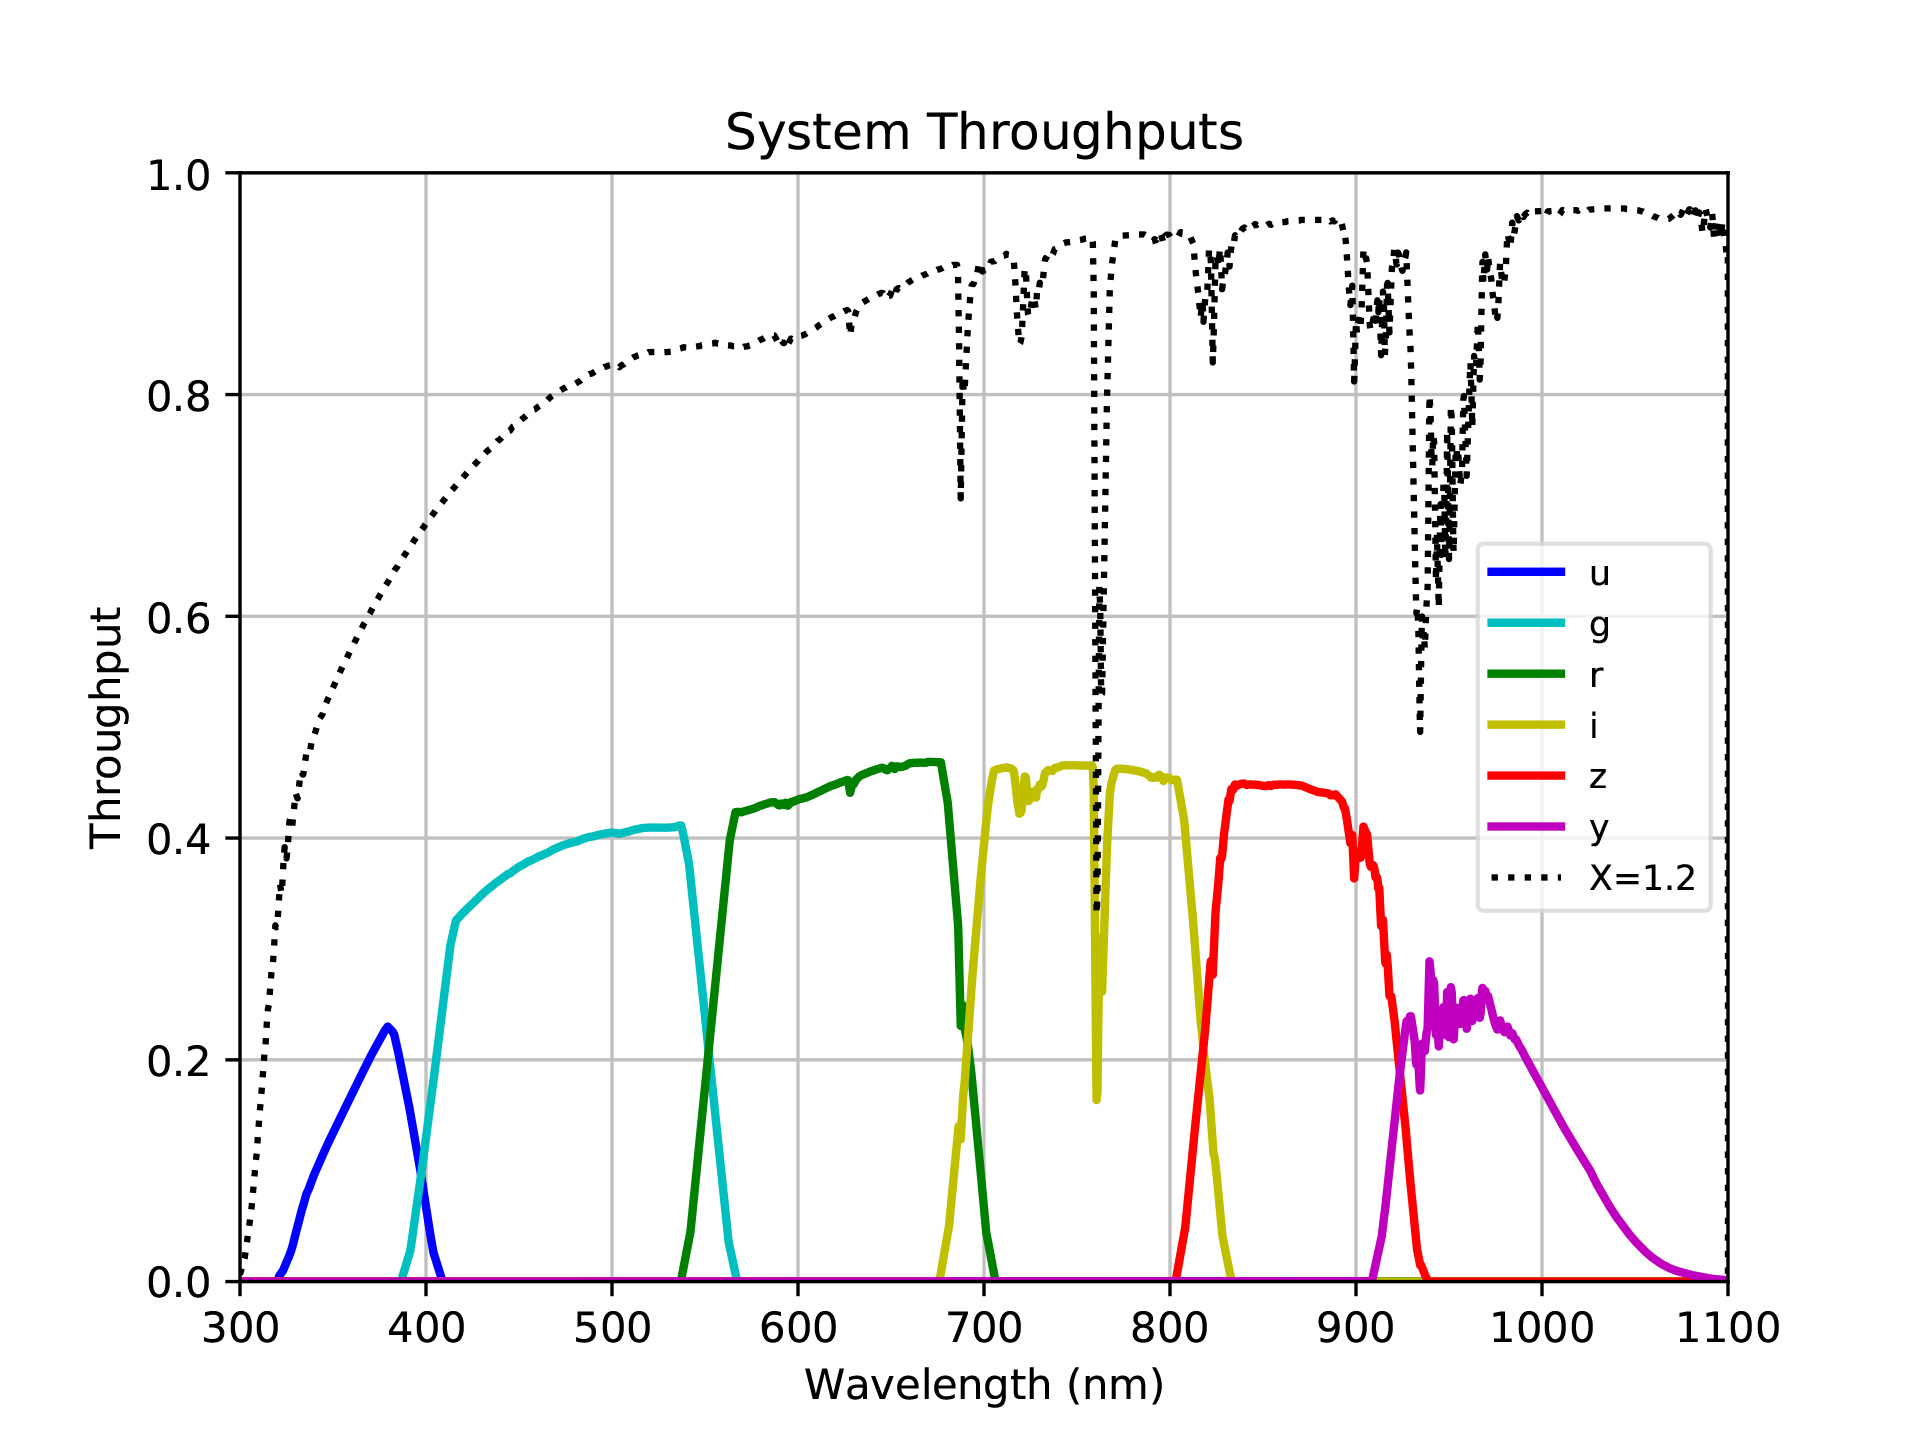

### Read and filter asteroids

Columns of the file:

In [2]:
data_file = data_dir + 'obs_sbn_X05_full.parquet'
columns = pq.read_schema(data_file).names
print_list(columns)

id, trksub, trkid, obsid, submission_id, submission_block_id, obs80, status,
ref, healpix, permid, provid, artsat, mode, stn, trx, rcv, sys, ctr, pos1, pos2,
pos3, poscov11, poscov12, poscov13, poscov22, poscov23, poscov33, prog, obstime,
ra, dec, rastar, decstar, obscenter, deltara, deltadec, dist, pa, rmsra, rmsdec,
rmsdist, rmspa, rmscorr, delay, rmsdelay, doppler, rmsdoppler, astcat, mag,
rmsmag, band, photcat, photap, nucmag, logsnr, seeing, exp, rmsfit, com, frq,
disc, subfrm, subfmt, prectime, precra, precdec, unctime, notes, remarks,
deprecated, localuse, nstars, prev_desig, prev_ref, rmstime, created_at,
updated_at, trkmpc, orbit_id, designation_asterisk, shapeocc, obssubid,
replacesobsid, group_id, vel1, fltr, vel3, vel2, obstime_text


### Filter data

Read all data:

In [3]:
columns = [
    'obstime', 'permid', 'provid',
    'ra', 'dec', 'band', 'mag', 'rmsmag'
]

df_full = pd.read_parquet(
    data_file,
    columns=columns,
)
print(f"Original number of observations: {len(df_full)}")

Original number of observations: 8078546


We will filter data having `provid` or `permid`:

In [4]:
df_set = df_full[~(df_full['provid'].isna() & df_full['permid'].isna())].reset_index(drop=True)
print(f"Number of observations with provid or permid: {len(df_set)}")

Number of observations with provid or permid: 8014721


Now I want only those with asteroidal `provid`, ie. obeying the pattern `CCYY LL[NN]` (eg. 2025 MN45):

In [5]:
asteroid_provid_pattern = re.compile(r'^\d{4} [A-Z]{2}\d+[A-Z]?$')
df_set = df_set[df_set['provid'].apply(lambda pid: bool(asteroid_provid_pattern.match(str(pid))))].reset_index(drop=True)
print(f"Number of observations with asteroid provid: {len(df_set)}")

provids = df_set['provid'].dropna().unique()
permids = df_set['permid'].dropna().unique()
bothids = df_set.dropna(subset=['permid','provid'])['provid'].unique()
print(f"Number of objects with provid:  {len(provids)}")
print(f"Number of objects with permid: {len(permids)}")
print(f"Number of objects with both ids: {len(bothids)}")
df_set.head()

Number of observations with asteroid provid: 7870711
Number of objects with provid:  297318
Number of objects with permid: 176882
Number of objects with both ids: 176903


,obstime,permid,provid,ra,dec,band,mag,rmsmag
0,2025-05-02 00:42:01.796,NaN,2025 MD8,186.158016,4.012876,i,23.096,0.124
1,2025-05-02 00:39:54.996,NaN,2025 MD8,186.158229,4.012886,i,22.927,0.127
2,2025-05-02 01:01:01.387,NaN,2025 MD8,186.156548,4.013182,i,23.055,0.105
3,2025-05-02 01:03:10.218,NaN,2025 MD8,186.156327,4.01323,i,23.059,0.129
4,2025-05-02 01:29:18.645,NaN,2025 MD8,186.154292,4.01363,r,22.911,0.072


Sort observations by date and convert data:

In [6]:
# Sort observations
df_set = df_set.sort_values(
    by=['provid', 'band', 'obstime'],
    ascending=[True, True, True]
).reset_index(drop=True)

# Convert data
cols = ['ra', 'dec', 'mag', 'rmsmag']
df_set[cols] = df_set[cols].apply(pd.to_numeric, errors='coerce')
df_set['night'] = df_set['obstime'].dt.floor('D')

df_set.head()

,obstime,permid,provid,ra,dec,band,mag,rmsmag,night
0,2026-01-05 08:33:53.126,2855,1931 TB2,236.107705,-26.066285,Li,18.641,0.0136,2026-01-05
1,2026-01-05 08:39:18.094,2855,1931 TB2,236.109156,-26.066696,Li,18.591,0.0165,2026-01-05
2,2026-01-05 08:44:42.950,2855,1931 TB2,236.110603,-26.067110,Li,18.567,0.0170,2026-01-05
3,2025-05-20 23:57:56.988,1232,1931 TF2,149.033158,0.736289,Lg,16.105,0.0100,2025-05-20
4,2025-05-21 00:02:22.012,1232,1931 TF2,149.033714,0.736253,Lg,16.094,0.0100,2025-05-21


Clean memory and compute RAM memory usage:

In [7]:
del(df_full)
total_sizeof_globals()

Total RAM used by notebook variables: 654.34 MB


Cross match orbital data:

In [8]:
df_elems = extract_orbital_elements_from_mpcorb(provids)
df_elems

,provid,number,name,H,G,epoch,epoch_jd,M,argperi,node,i,e,n,a,nobs,nopp,arc,rms
0,1931 TB2,2855,Bastian,13.29,0.15,K2669,2.460524e+06,173.63728,100.33561,338.96726,8.14295,0.169013,0.25648098,2.453386,4031,26,1931-2026,0.73
1,1931 TF2,1232,Cortusa,10.30,0.15,K2669,2.461135e+06,11.47022,340.66262,260.69982,10.37600,0.142260,0.17421345,3.175033,6661,45,1930-2026,0.65
2,1931 TJ1,3379,Oishi,13.37,0.15,K2669,2.461174e+06,7.23223,304.44094,146.71841,2.85411,0.130547,0.27268981,2.355176,5033,30,1931-2026,0.74
3,1931 TN1,1941,Wild,11.83,0.15,K2669,2.461451e+06,328.62697,303.07122,60.39420,3.95630,0.288755,0.12517551,3.957824,3890,36,1915-2026,0.75
4,1931 TS1,5072,Hioki,12.92,0.15,K2669,2.461057e+06,28.42841,2.06104,10.83959,2.01352,0.082769,0.19861493,2.909342,5486,31,1931-2026,0.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294974,2026 KB6,<NA>,,7.07,0.15,K2669,2.452690e+06,19.92996,116.40284,72.05461,31.97982,0.351578,0.00234173,56.162249,13,1,48 days,0.09
294975,2026 KO6,<NA>,,7.26,0.15,K2669,2.449798e+06,46.02190,37.36887,138.84223,8.41402,0.132952,0.00403637,39.066869,12,1,48 days,0.07
294976,2026 OL3,<NA>,,23.19,0.15,K2669,2.461300e+06,321.27148,83.62188,301.54246,2.89417,0.598438,0.38955004,1.856780,22,1,12 days,0.45
294977,2026 RL12,<NA>,,18.02,0.15,K2669,2.461018e+06,32.95341,312.72441,334.80783,13.34427,0.138322,0.18028558,3.103336,65,6,2004-2026,0.37


In [9]:
total_sizeof_globals()

Total RAM used by notebook variables: 706.27 MB


### Asteroid Lightcurve

Select asteroid:

- Either by permid:

In [10]:
permid = '347940'
provid = df_set[df_set['permid'] == permid]['provid'].unique()[0]
try:
    name = df_elems[df_elems['number'] == float(permid)]['name'].unique()[0]
except:
    name = 'Unknown'
print(f"Asteroid: {permid} {name} ({provid})")
#

Asteroid: 347940 Jorgezuluaga (2003 FZ128)


- Or by provid:

In [86]:
provid = '2025 MM82'
#provid = '2025 MT24'

Get all observations:

In [87]:
df_obj = df_set[df_set['provid'] == provid]
print(f"Number of observations: {len(df_obj)}")

t0 = df_obj['obstime'].iloc[0]
df_obj['t_days'] = (df_obj['obstime'] - t0).dt.total_seconds() / 86400.0

print(f"Total observations of Asteroid {provid}: {len(df_obj)}")
print(f"Observing arc: {(df_obj['obstime'].max() - t0).total_seconds() / 86400.0:.2f} days")
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

Number of observations: 464
Total observations of Asteroid 2025 MM82: 464
Observing arc: 9.02 days
Observations per band: {'Lr': 191, 'Li': 134, 'Lg': 109, 'g': 18, 'r': 12}


Plot all observations:

/var/folders/xn/75ncx53144919w099wx5x5mw0000gn/T/ipykernel_35159/556614735.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)


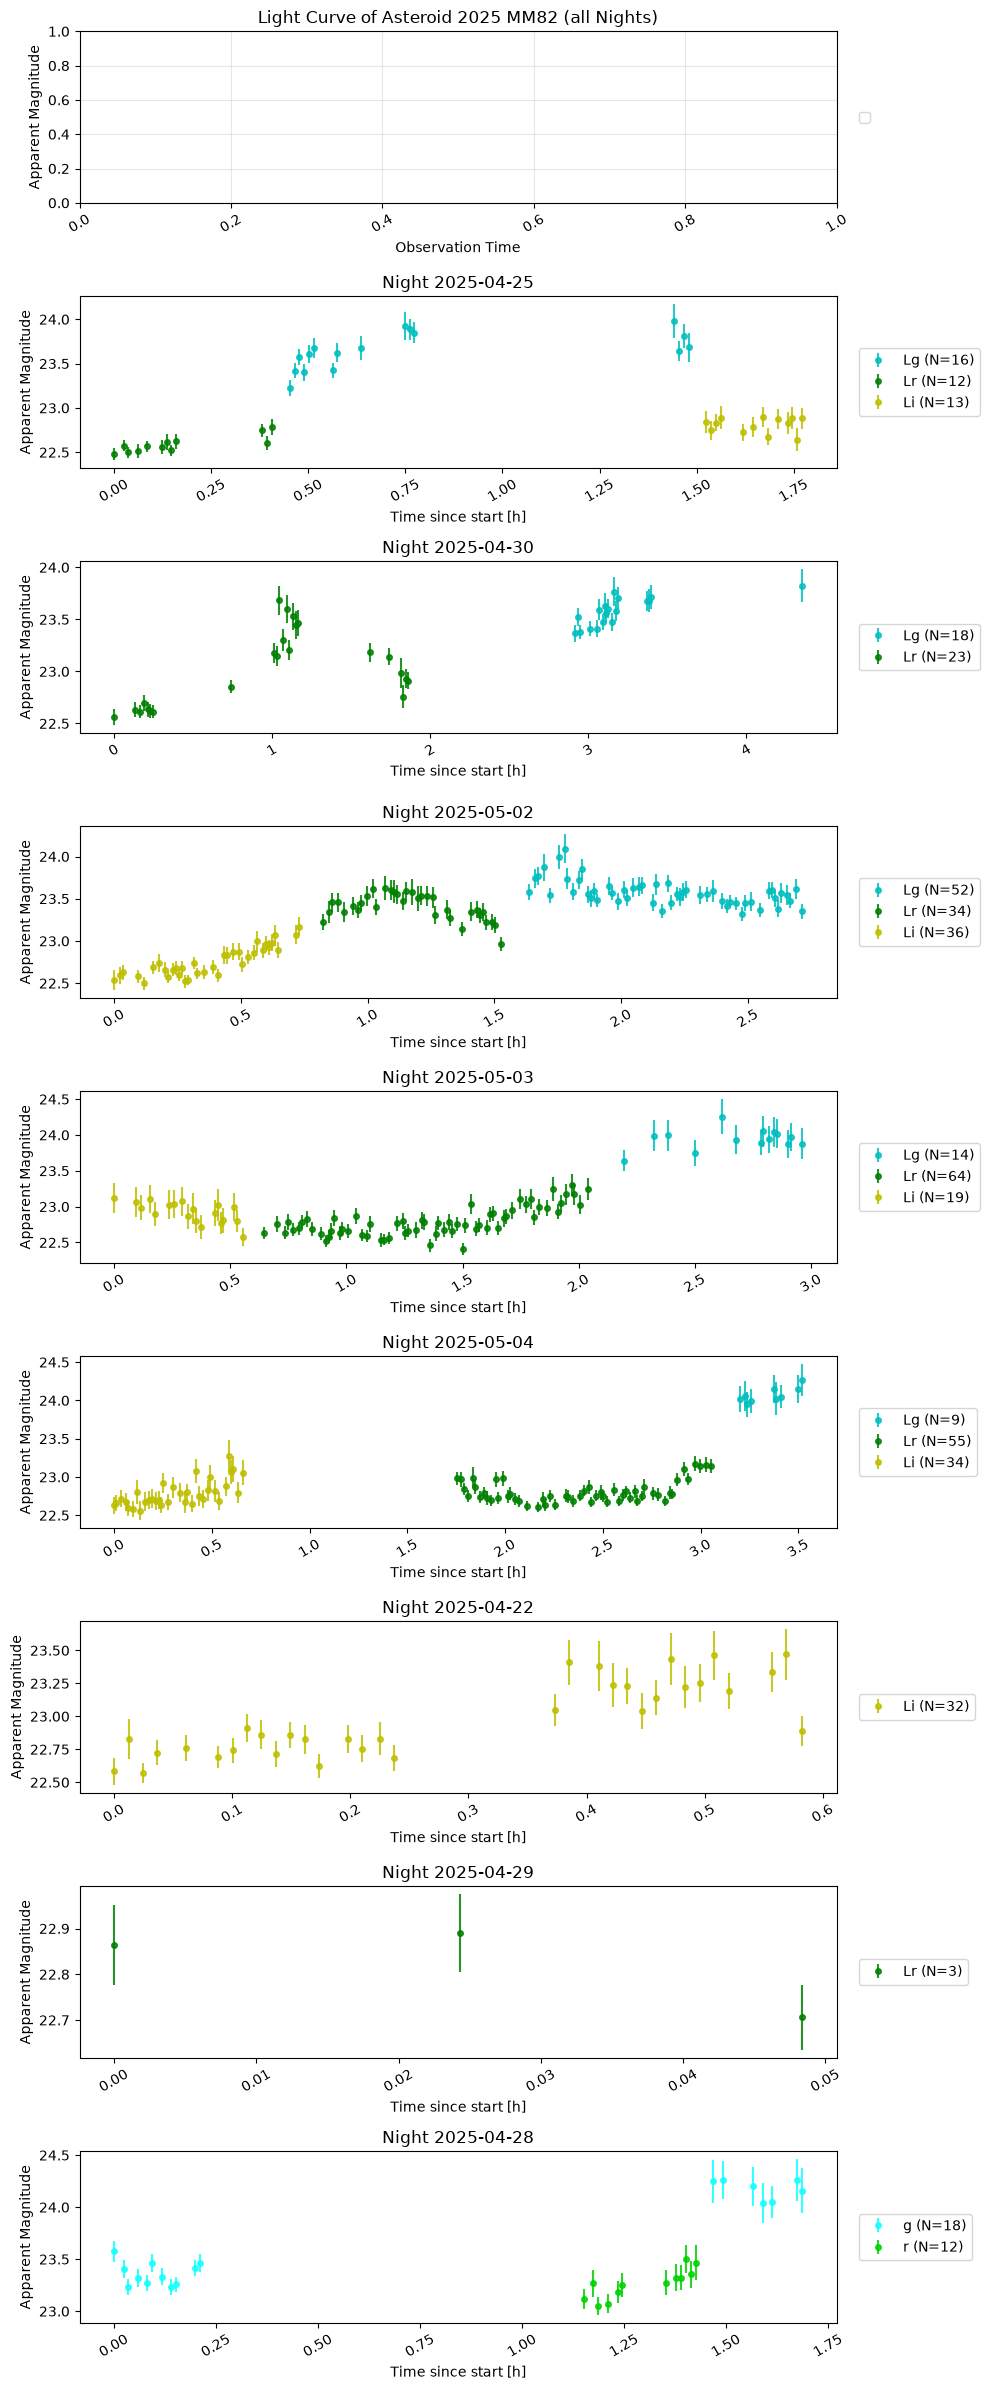

In [88]:
verbose = 0
nights = df_obj.night.unique()
n_nights = len(nights)

fig, axs = plt.subplots(n_nights + 1, 1, figsize=(10, 3*n_nights))

# All data
ax = axs[0]
df_obj = df_obj.copy()
for b in bands:
    sb = df_obj[df_obj['band'] == b]
    if len(sb) > 0:
        ax.errorbar(sb['obstime'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax.set_xlabel(f"Observation Time")
ax.set_ylabel('Apparent Magnitude')
ax.tick_params(axis='x', rotation=30)
ax.set_title(f"Light Curve of Asteroid {provid} (all Nights)")
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
ax.grid(True, alpha=0.3)

for i, night in enumerate(nights):
    night_str = pd.to_datetime(night).strftime('%Y-%m-%d')
    if verbose:print(f"Processing night {night_str}")
    ax = axs[i+1]
    t_night = df_obj[df_obj['night'] == night].copy()
    t_night_0 = min(t_night['obstime'])
    t_night['h'] = (t_night['obstime'] - t_night_0).dt.total_seconds() / 3600.0
    for b in all_bands:
        sb = t_night[t_night['band'] == b]
        if len(sb) > 0:
            if verbose:print(f"\tBand {b}: {len(sb)} observations")
            ax.errorbar(sb['h'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                        label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)
    
    ax.set_title(f"Night {night_str}")
    ax.set_xlabel(f"Time since start [h]")
    ax.set_ylabel('Apparent Magnitude')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
    ax.tick_params(axis='x', rotation=30)

fig.tight_layout()
fig.savefig(fig_dir + f"lightcurve_allnights_{provid.replace(' ', '_')}.png", dpi=300)

### Periodogram

Now we get the rotation period from a Lomb-Scargle periodogram.

We can choose which band:

In [89]:
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

Observations per band: {'Lr': 191, 'Li': 134, 'Lg': 109, 'g': 18, 'r': 12}


Photometric period: 2.51 hours
Derived asteroid rotation period: 5.02 hours

All periodogram peaks with >80% of main peak power:
[0] Rotational Period = 10.28 h | Power = 0.801
[1] Rotational Period = 5.61 h | Power = 0.940
[2] Rotational Period = 5.02 h | Power = 1.000
[3] Rotational Period = 4.54 h | Power = 0.975
[4] Rotational Period = 4.15 h | Power = 0.874


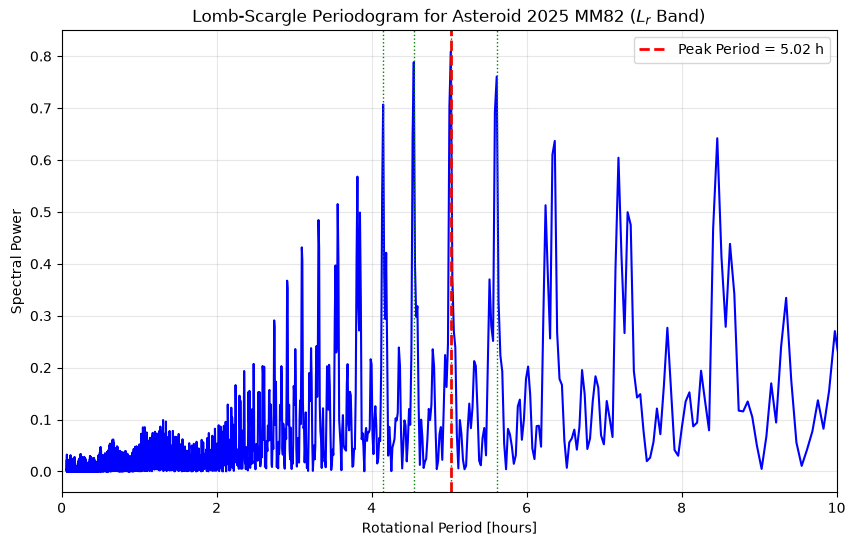

In [90]:
band = ['Lr', 'r']
# band = ['Lg', 'g']
df_band = df_obj[(df_obj['band'] == band[0]) | (df_obj['band'] == band[1])].copy()
t_band = df_band['t_days'].values
y_band = df_band['mag'].values
dy_band = df_band['rmsmag'].fillna(0.01).values

# Frequency grid: 1.0 to 10.0 cycles/day (corresponding to periods from 2.4 to 24 hours)
periods = [2/60, 24] # in hours
freq_grid = np.linspace(24/periods[1], 24/periods[0], 20000)
ls_band = LombScargle(t_band, y_band, dy_band)
power = ls_band.power(freq_grid)

main_peak_power = np.max(power)
best_freq = freq_grid[np.argmax(power)]
best_phot_period = 24.0 / best_freq
best_rot_period = 2.0 * best_phot_period  # Double-peaked rotational period
print(f"Photometric period: {best_phot_period:.2f} hours")
print(f"Derived asteroid rotation period: {best_rot_period:.2f} hours")

# Find periodogram peaks
peaks, _ = find_peaks(power)
threshold = 0.8 * main_peak_power
high_power_indices = np.where(power >= threshold)[0]
high_power_peaks = np.intersect1d(peaks, high_power_indices)

print(f"\nAll periodogram peaks with >80% of main peak power:")

all_rot_periods = []
peak_data = []
for i, idx in enumerate(high_power_peaks):
    freq = freq_grid[idx]
    ph_per = 24.0 / freq
    rot_per = 2.0 * ph_per
    rel_pwr = power[idx] / main_peak_power
    all_rot_periods = np.append(all_rot_periods, rot_per)
    peak_data.append({
        "frequency": freq,
        "rotational_period_h": rot_per,
        "relative_power": rel_pwr
    })
    print(f"[{i}] Rotational Period = {rot_per:.2f} h | Power = {rel_pwr:.3f}")
df_peaks = pd.DataFrame(peak_data).sort_values(by='relative_power', ascending=False).reset_index(drop=True) 

fig, ax = plt.subplots(figsize=(10, 6))

period_grid_hours = (24.0 / freq_grid) * 2.0  # Converted to rotational period
ax.plot(period_grid_hours, power, color='b', lw=1.5)
ax.axvline(best_rot_period, color='r', linestyle='--', lw=2, label=f'Peak Period = {best_rot_period:.2f} h')
for period in all_rot_periods:
    ax.axvline(period, color='g', linestyle=':', alpha=1, lw=1)

ax.set_xlabel('Rotational Period [hours]')
ax.set_ylabel('Spectral Power')
ax.set_title(f'Lomb-Scargle Periodogram for Asteroid {provid} ($L_r$ Band)')
ax.set_xlim(0, 10)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)


In [91]:
df_peaks

,frequency,rotational_period_h,relative_power
0,9.556528,5.022745,1.000000
1,10.563178,4.544087,0.974598
2,8.549877,5.614116,0.940216
3,11.569828,4.148722,0.873694
4,4.667083,10.284796,0.801117


Selected peak:

In [92]:
isel = 0
freq_sel = df_peaks.iloc[isel]['frequency']
per_sel = df_peaks.iloc[isel]['rotational_period_h']
rel_pwr = df_peaks.iloc[isel]['relative_power']
print(f"[{isel}] Rotational Period = {per_sel:.2f} h | Power = {rel_pwr:.3f}")


[0] Rotational Period = 5.02 h | Power = 1.000


Folded light-curve:

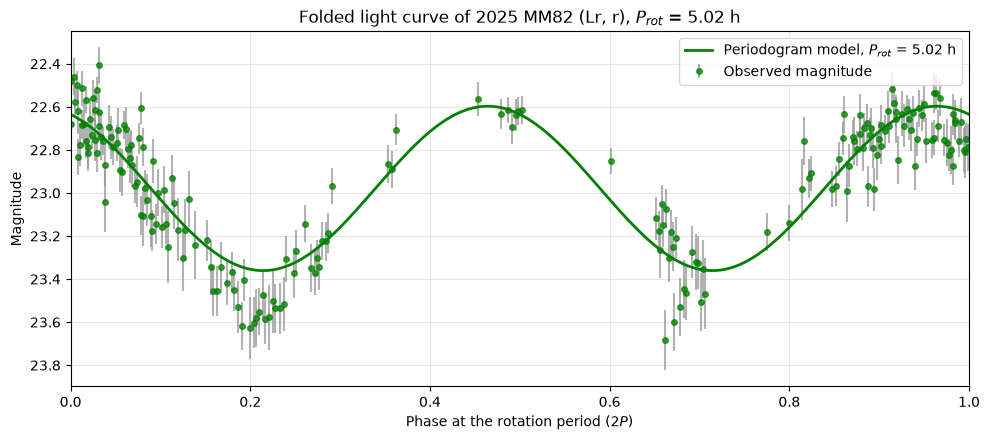

In [93]:
t0 = t_band.min()
phase = np.mod((t_band - t0) * freq_sel, 1.0)
phase_grid = np.linspace(0, 1, 400)
y_model = ls_band.model(t0 + phase_grid / freq_sel, freq_sel)

# Same model sampled across one rotation (two photometric cycles)
phase_rot = np.mod((t_band - t0) * freq_sel / 2.0, 1.0)
phase_rot_grid = np.linspace(0, 1, 400)
y_model_rot = ls_band.model(t0 + phase_rot_grid * 2.0 / freq_sel, freq_sel)

fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))

b = band if isinstance(band, str) else band[0]
curve_color = band_colors.get(b, 'k')
ax.errorbar(
    phase_rot, y_band, yerr=dy_band, fmt='o', ms=4, alpha=0.75,
    color=curve_color, ecolor='0.6', label='Observed magnitude'
)
ax.plot(
    phase_rot_grid, y_model_rot, color=curve_color, lw=2,
    label=f'Periodogram model, $P_{{rot}}$ = {best_rot_period:.2f} h'
)
ax.set_xlabel('Phase at the rotation period ($2P$)')
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', frameon=True)
ax.set_ylabel('Magnitude')
ax.set_title(f"Folded light curve of {provid} ({', '.join(band)}), $P_{{rot}}$ = {best_rot_period:.2f} h")
fig.tight_layout()
fig.savefig(fig_dir + f"phase_model_{provid.replace(' ', '_')}.png", dpi=300)

Now let's see the sine curve and the data:

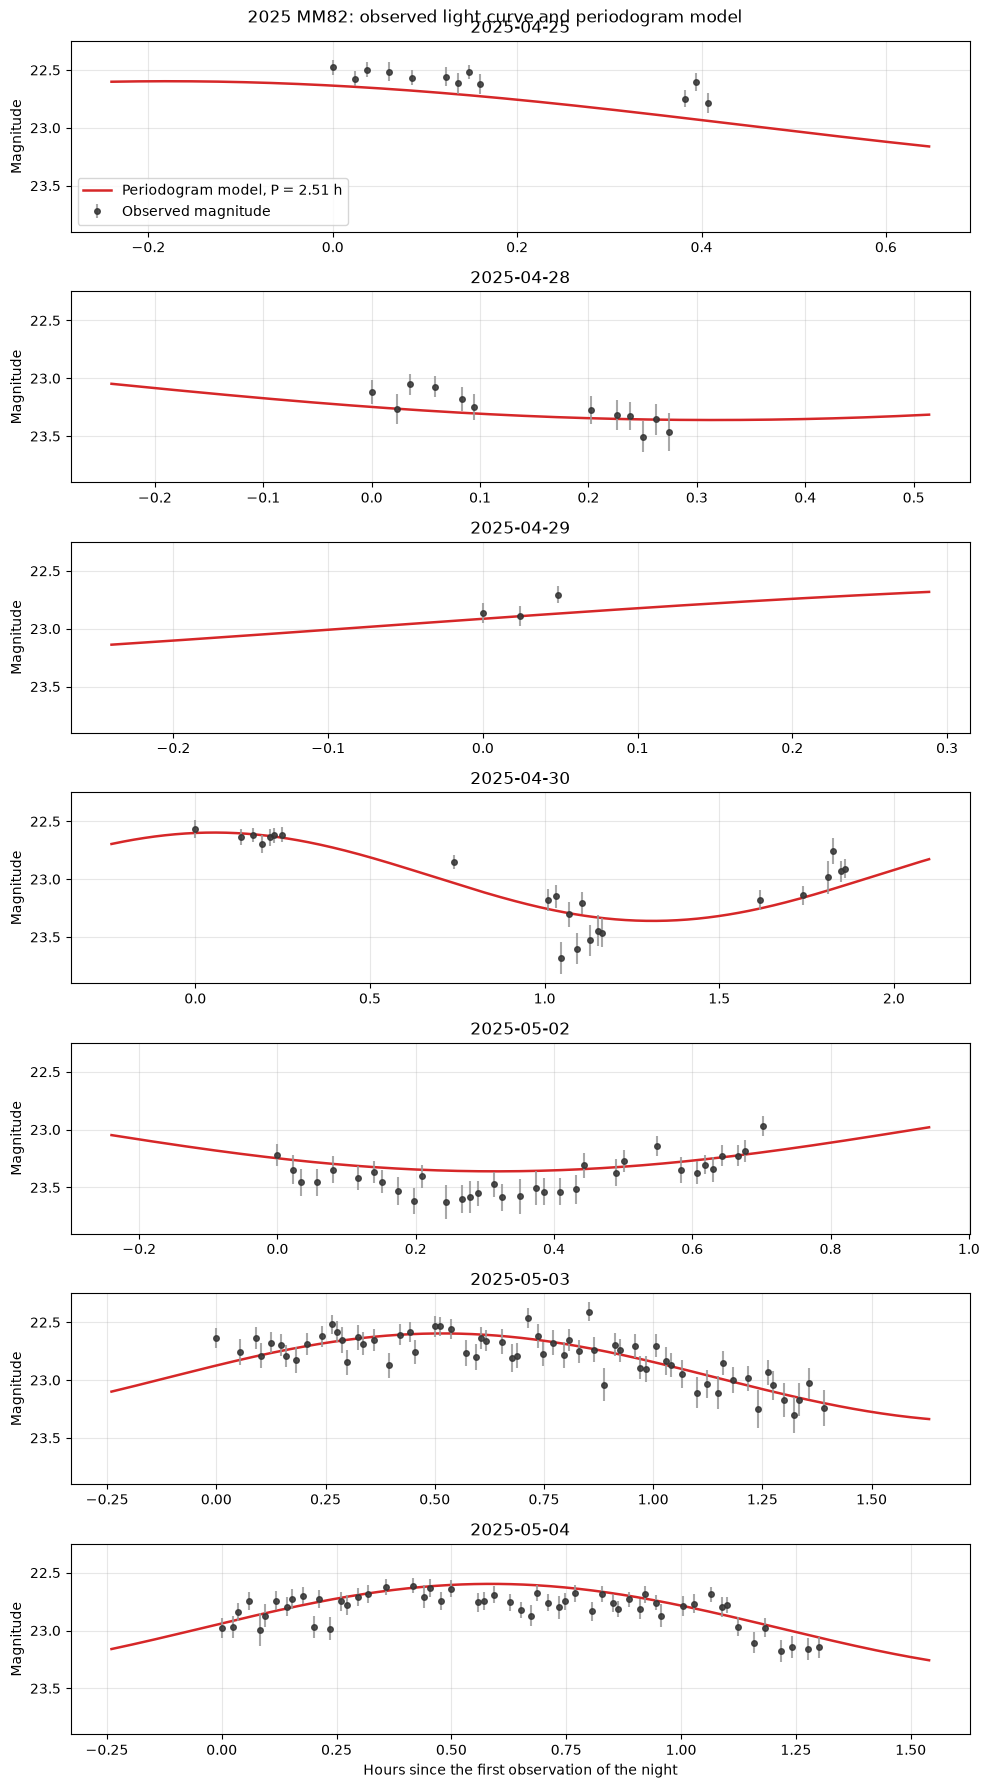

In [94]:
nights_band = df_band['night'].drop_duplicates().sort_values()
n_nights_band = len(nights_band)
fig, axs = plt.subplots(n_nights_band, 1, figsize=(10, 2.6 * n_nights_band), sharey=True)
if n_nights_band == 1:
    axs = [axs]

for ax, night in zip(axs, nights_band):
    sel = df_band['night'] == night
    t_night = df_band.loc[sel, 't_days'].to_numpy()
    y_night = df_band.loc[sel, 'mag'].to_numpy()
    dy_night = df_band.loc[sel, 'rmsmag'].fillna(0.01).to_numpy()
    t_left, t_right = t_night.min(), t_night.max()
    pad = max(0.01, 0.05 * (t_right - t_left))
    t_grid = np.linspace(t_left - pad, t_right + pad, 400)
    y_grid = ls_band.model(t_grid, best_freq)
    hours = (t_night - t_left) * 24.0
    hours_grid = (t_grid - t_left) * 24.0
    ax.errorbar(
        hours, y_night, yerr=dy_night, fmt='o', ms=4, alpha=0.85,
        color='0.2', ecolor='0.6', label='Observed magnitude', zorder=3
    )
    ax.plot(
        hours_grid, y_grid, color='C3', lw=1.8,
        label=f'Periodogram model, P = {best_phot_period:.2f} h', zorder=2
    )
    ax.set_title(pd.to_datetime(night).strftime('%Y-%m-%d'))
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)

axs[0].invert_yaxis()
axs[0].legend(loc='best', frameon=True)
axs[-1].set_xlabel('Hours since the first observation of the night')
fig.suptitle(f'{provid}: observed light curve and periodogram model')
fig.tight_layout()
fig.savefig(fig_dir + f'timemodel_{provid.replace(" ", "_")}.png', dpi=300)


Brightest magnitude of each filter (m_max):
  g: 23.226
  r: 22.408
  i: 22.498


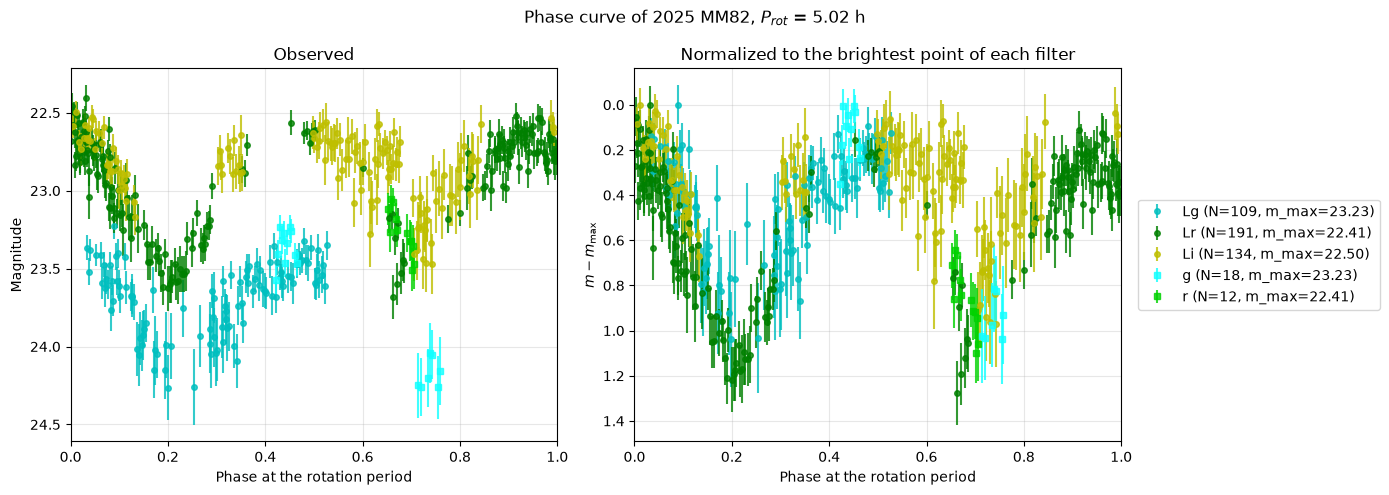

In [95]:
alias = {'Lg': 'g', 'Lr': 'r', 'Li': 'i', 'Lz': 'z', 'Ly': 'y', 'Lu': 'u'}
filt = lambda b: alias.get(b, b)

present = [b for b in all_bands if (df_obj['band'] == b).any()]
m_max = {}
for f in dict.fromkeys(filt(b) for b in present):
    members = [b for b in present if filt(b) == f]
    m_max[f] = df_obj[df_obj['band'].isin(members)]['mag'].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
print('Brightest magnitude of each filter (m_max):')
for f, m in m_max.items():
    print(f'  {f}: {m:.3f}')

for b in present:
    sb = df_obj[df_obj['band'] == b]
    phase_b = np.mod((sb['t_days'].to_numpy() - t0) * freq_sel / 2.0, 1.0)
    dy = sb['rmsmag'].fillna(0.01)
    marker = 'o' if b.startswith('L') else 's'
    m = m_max[filt(b)]
    style = dict(fmt=marker, ms=4, alpha=0.8, color=band_colors.get(b, 'k'),
                 label=f'{b} (N={len(sb)}, m_max={m:.2f})')
    axes[0].errorbar(phase_b, sb['mag'], yerr=dy, **style)
    axes[1].errorbar(phase_b, sb['mag'] - m, yerr=dy, **style)

axes[0].set_ylabel('Magnitude')
axes[0].set_title('Observed')
axes[1].set_ylabel(r'$m - m_{\mathrm{max}}$')
axes[1].set_title('Normalized to the brightest point of each filter')
for ax in axes:
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('Phase at the rotation period')
    ax.grid(True, alpha=0.3)
axes[1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)
fig.suptitle(f'Phase curve of {provid}, $P_{{rot}}$ = {per_sel:.2f} h')
fig.tight_layout()
fig.savefig(fig_dir + f'phase_allbands_{provid.replace(" ", "_")}.png', dpi=300)



### Average color indexes for asteroid

In [96]:
# Night with observations in the largest number of filters.
# Lg/g, Lr/r, ... are the same filter. If several nights tie, use the one with more measurements.
alias = {'Lg': 'g', 'Lr': 'r', 'Li': 'i', 'Lz': 'z', 'Ly': 'y', 'Lu': 'u'}
filt_order = ['u', 'g', 'r', 'i', 'z', 'y']
filt = lambda b: alias.get(b, b)

df_color = df_obj.dropna(subset=['mag', 'band']).copy()
df_color['filt'] = df_color['band'].map(filt)
rms = df_color['rmsmag'].to_numpy(float)
df_color['rmsmag'] = np.where(np.isfinite(rms) & (rms > 0), rms, 0.01)

rows = []
for night, g in df_color.groupby('night'):
    present = [f for f in filt_order if f in set(g['filt'])]
    rows.append({'night': night, 'n_filt': len(present), 'n_obs': len(g),
                 'filters': ', '.join(present)})
df_nights = pd.DataFrame(rows).sort_values(['n_filt', 'n_obs'], ascending=[False, False])
print('Filters per night:')
print(df_nights.assign(night=df_nights['night'].dt.strftime('%Y-%m-%d')).to_string(index=False))

best = df_nights.iloc[0]
night_best = best['night']
n_best = int(best['n_filt'])
tied = df_nights[df_nights['n_filt'] == n_best]
night_label = pd.to_datetime(night_best).strftime('%Y-%m-%d')
print(f"\nSelected night: {night_label} ({n_best} filters, N={int(best['n_obs'])})")
if len(tied) > 1:
    others = ', '.join(pd.to_datetime(tied['night']).dt.strftime('%Y-%m-%d'))
    print(f"Nights with that many filters: {others}. Using the one with the most observations.")

g = df_color[df_color['night'] == night_best]
mags = {}
print('\nWeighted-mean magnitude:')
for f in [f for f in filt_order if (g['filt'] == f).any()]:
    sub = g[g['filt'] == f]
    m, s = wmean(sub['mag'], sub['rmsmag'])
    bands = ', '.join(sorted(sub['band'].unique()))
    mags[f] = (m, s)
    print(f"  {f}: {m:.3f} ± {s:.3f}  (N={len(sub)}, bands={bands})")

if 'r' not in mags:
    print('\nThis night has no r-band observations, so colors relative to r are not defined.')
else:
    mr, sr = mags['r']
    print('\nAverage color indexes (m - m_r):')
    for f, (mb, sb) in mags.items():
        if f == 'r':
            continue
        print(f"  {f} - r = {mb - mr:.3f} ± {np.sqrt(sb**2 + sr**2):.3f}")

Filters per night:
     night  n_filt  n_obs filters
2025-05-02       3    122 g, r, i
2025-05-04       3     98 g, r, i
2025-05-03       3     97 g, r, i
2025-04-25       3     41 g, r, i
2025-04-30       2     41    g, r
2025-04-28       2     30    g, r
2025-04-22       1     32       i
2025-04-29       1      3       r

Selected night: 2025-05-02 (3 filters, N=122)
Nights with that many filters: 2025-05-02, 2025-05-04, 2025-05-03, 2025-04-25. Using the one with the most observations.

Weighted-mean magnitude:
  g: 23.543 ± 0.014  (N=52, bands=Lg)
  r: 23.368 ± 0.018  (N=34, bands=Lr)
  i: 22.715 ± 0.014  (N=36, bands=Li)

Average color indexes (m - m_r):
  g - r = 0.175 ± 0.023
  i - r = -0.653 ± 0.023


### Data completion using average color indices

In [97]:
# Estimate the missing filters at each epoch with the average colors from the selected night.
# m_b = m_a + (c_b - c_a), where c_f = <m_f> - <m_r> and c_r = 0.
if 'r' not in mags:
    raise ValueError('The selected night has no r-band observations, so the missing filters cannot be estimated.')

color = {f: mags[f][0] - mags['r'][0] for f in mags}
sig_mean = {f: (0.0 if f == 'r' else mags[f][1]) for f in mags}
long_name = {short: long for long, short in alias.items()}

print(f'Color indexes from {night_label} (m - m_r):')
for f in filt_order:
    if f in color and f != 'r':
        err = np.sqrt(mags[f][1]**2 + mags['r'][1]**2)
        print(f'  {f} - r = {color[f]:+.3f} ± {err:.3f}')

real = df_obj.dropna(subset=['mag', 'band']).copy()
real['filt'] = real['band'].map(filt)
real['estimated'] = False
real['source_filt'] = pd.NA
rms = real['rmsmag'].to_numpy(float)
real['rmsmag'] = np.where(np.isfinite(rms) & (rms > 0), rms, 0.01)

sources = real[real['filt'].isin(color)].copy()
pieces = [real]
for b, cb in color.items():
    src = sources[sources['filt'] != b].copy()
    if src.empty:
        continue
    sig_a = src['filt'].map(sig_mean).to_numpy(float)
    src['mag'] = src['mag'].to_numpy(float) + cb - src['filt'].map(color).to_numpy(float)
    src['rmsmag'] = np.sqrt(src['rmsmag'].to_numpy(float)**2 + sig_mean[b]**2 + sig_a**2)
    src['source_filt'] = src['filt']
    src['filt'] = b
    src['band'] = long_name.get(b, b)
    src['estimated'] = True
    pieces.append(src)

df_obj_comp = pd.concat(pieces, ignore_index=True)
df_obj_comp = df_obj_comp.sort_values(['obstime', 'filt', 'estimated']).reset_index(drop=True)

print(f'\ndf_obj_comp: {(~df_obj_comp.estimated).sum()} observed + {df_obj_comp.estimated.sum()} estimated = {len(df_obj_comp)} rows')
summary = (df_obj_comp.groupby(['filt', 'estimated']).size()
           .unstack(fill_value=0)
           .rename(columns={False: 'observed', True: 'estimated'}))
print(summary.reindex([f for f in filt_order if f in summary.index]).to_string())

Color indexes from 2025-05-02 (m - m_r):
  g - r = +0.175 ± 0.023
  i - r = -0.653 ± 0.023

df_obj_comp: 464 observed + 928 estimated = 1392 rows
estimated  observed  estimated
filt                          
g               127        337
r               203        261
i               134        330


### Computing the gray channel

In [98]:
# Gray channel Lk: magnitude of the summed flux of every filter available at that epoch.
# f ∝ 10^(-0.4 m), so m_Lk = -2.5 log10(Σ 10^(-0.4 m_f)).
base = df_obj_comp[df_obj_comp['band'] != 'Lk'].copy()
sig_mu = {f: mags[f][1] for f in mags}

rows = []
for obstime, g in base.groupby('obstime', sort=False):
    g = g.sort_values('estimated').groupby('filt', as_index=False).first().reset_index(drop=True)
    mag = g['mag'].to_numpy(float)
    flux = 10.0 ** (-0.4 * mag)
    ftot = flux.sum()
    w = flux / ftot
    mag_k = -2.5 * np.log10(ftot)

    coef_obs, coef_mu, obs_rms = {}, {}, {}
    for i in range(len(g)):
        row = g.iloc[i]
        f, wi = row['filt'], w[i]
        if not row['estimated']:
            coef_obs[f] = coef_obs.get(f, 0.0) + wi
            obs_rms[f] = row['rmsmag']
        else:
            a = row['source_filt']
            coef_obs[a] = coef_obs.get(a, 0.0) + wi
            coef_mu[f] = coef_mu.get(f, 0.0) + wi
            coef_mu[a] = coef_mu.get(a, 0.0) - wi
            if a not in obs_rms:
                obs_rms[a] = g.loc[(g['filt'] == a) & (~g['estimated']), 'rmsmag'].iloc[0]

    var = sum((c * obs_rms[f]) ** 2 for f, c in coef_obs.items())
    var += sum((c * sig_mu[f]) ** 2 for f, c in coef_mu.items() if f in sig_mu)

    anchor = g.loc[~g['estimated']].iloc[0] if (~g['estimated']).any() else g.iloc[0]
    out = anchor.copy()
    present = [f for f in filt_order if f in set(g['filt'])]
    out['band'] = 'Lk'
    out['filt'] = 'k'
    out['mag'] = mag_k
    out['rmsmag'] = np.sqrt(var)
    out['estimated'] = True
    out['source_filt'] = '+'.join(present)
    rows.append(out)

df_lk = pd.DataFrame(rows)
df_obj_comp = pd.concat([base, df_lk], ignore_index=True)
df_obj_comp = df_obj_comp.sort_values(['obstime', 'filt', 'estimated']).reset_index(drop=True)

band_colors['Lk'] = '#808080'
if 'Lk' not in all_bands:
    all_bands.append('Lk')

print(f'Lk: {len(df_lk)} epochs, summing {df_lk["source_filt"].iloc[0]}')
print(f'm_Lk median = {df_lk["mag"].median():.3f}  '
      f'(range {df_lk["mag"].min():.3f} to {df_lk["mag"].max():.3f})')


Lk: 464 epochs, summing g+r+i
m_Lk median = 21.912  (range 20.994 to 22.709)


### Plot completed data:

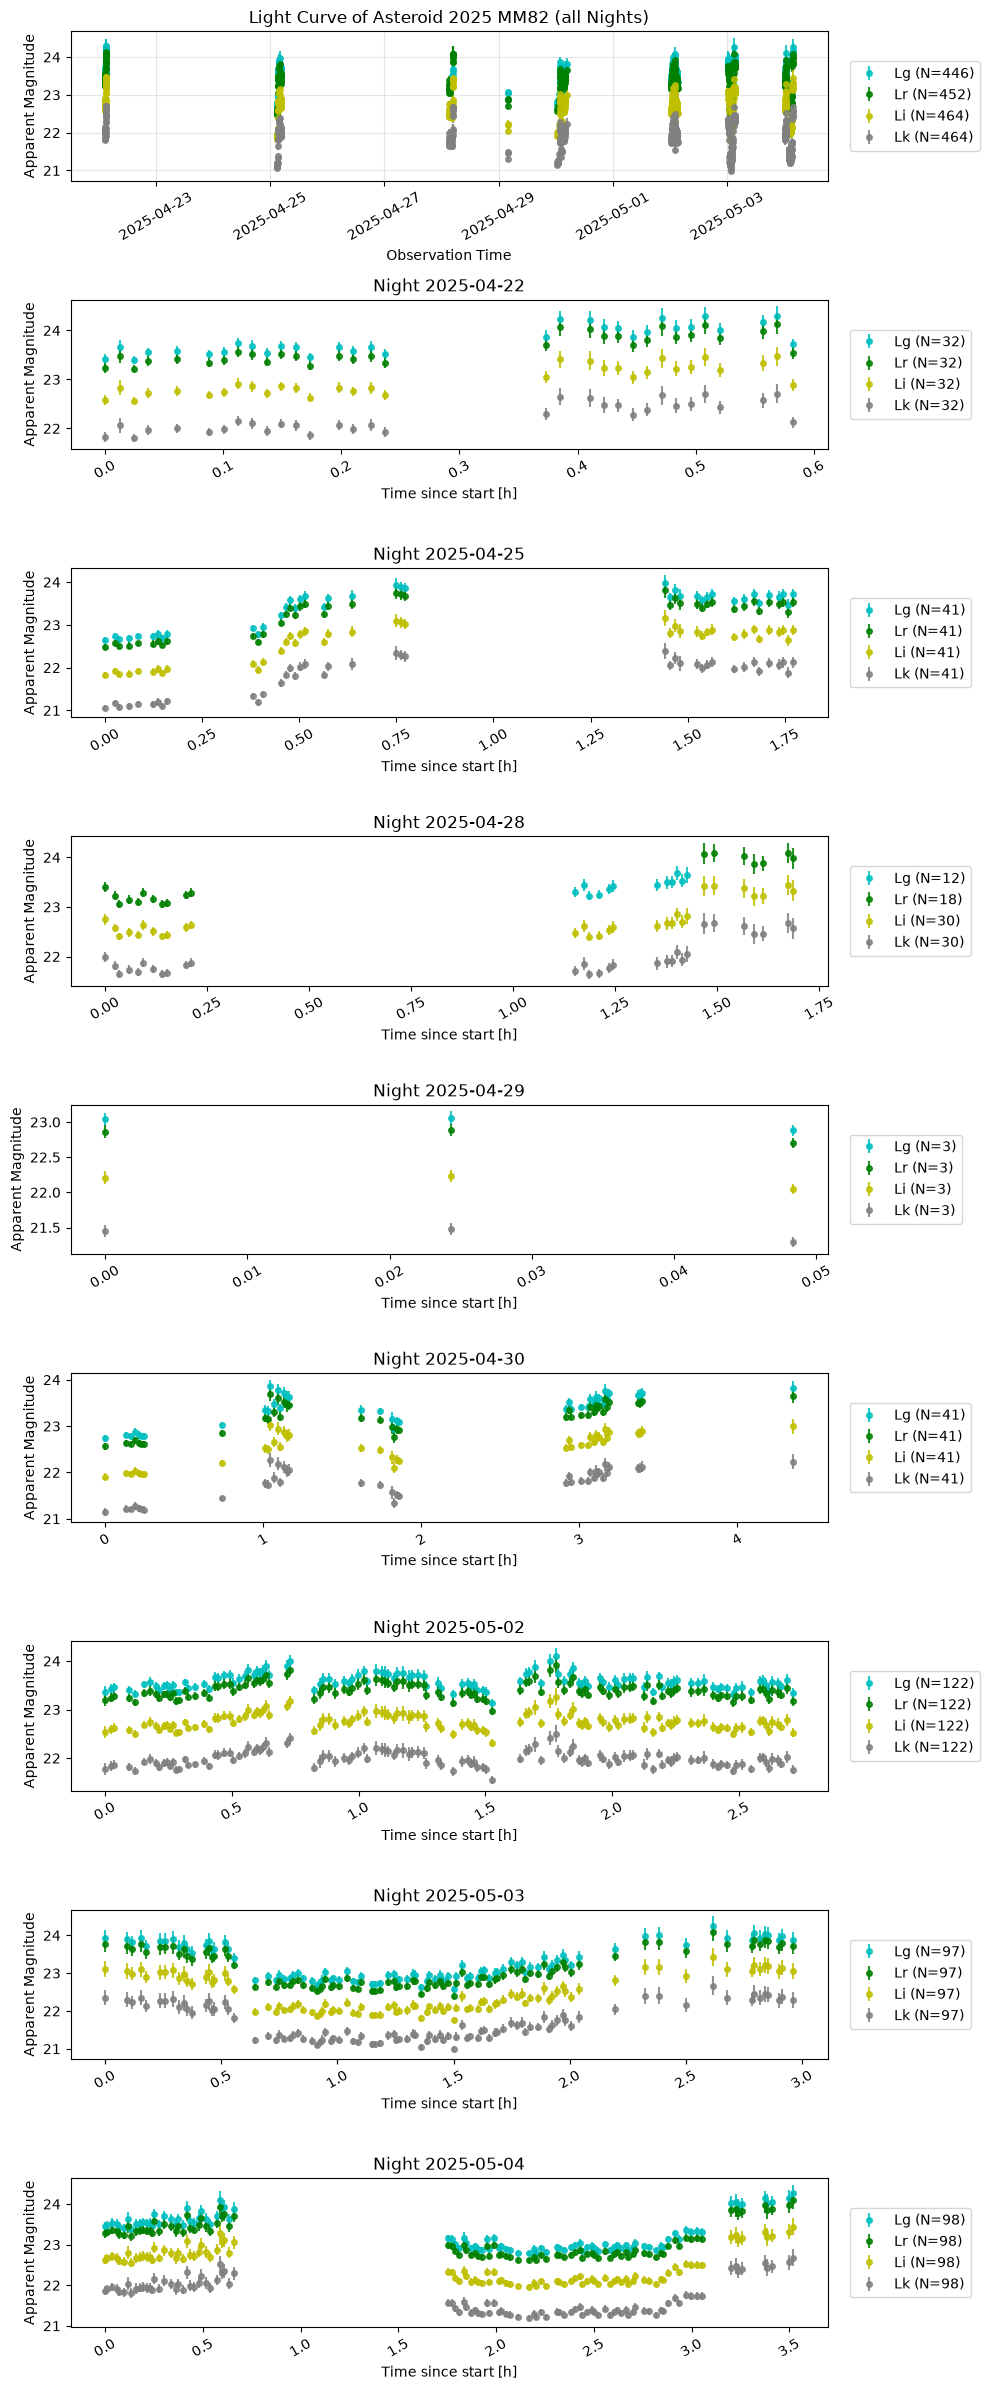

In [99]:
verbose = 0
nights = df_obj_comp.night.unique()
n_nights = len(nights)

fig, axs = plt.subplots(n_nights + 1, 1, figsize=(10, 3*n_nights))

# All data
ax = axs[0]
df_obj_comp = df_obj_comp.copy()
for b in all_bands:
    if 'L' not in b:continue
    sb = df_obj_comp[df_obj_comp['band'] == b]
    if len(sb) > 0:
        ax.errorbar(sb['obstime'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax.set_xlabel(f"Observation Time")
ax.set_ylabel('Apparent Magnitude')
ax.tick_params(axis='x', rotation=30)
ax.set_title(f"Light Curve of Asteroid {provid} (all Nights)")
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
ax.grid(True, alpha=0.3)

for i, night in enumerate(nights):
    night_str = pd.to_datetime(night).strftime('%Y-%m-%d')
    if verbose:print(f"Processing night {night_str}")
    ax = axs[i+1]
    t_night = df_obj_comp[df_obj_comp['night'] == night].copy()
    t_night_0 = min(t_night['obstime'])
    t_night['h'] = (t_night['obstime'] - t_night_0).dt.total_seconds() / 3600.0
    for b in all_bands:
        if 'L' not in b:continue
        sb = t_night[t_night['band'] == b]
        if len(sb) > 0:
            if verbose:print(f"\tBand {b}: {len(sb)} observations")
            ax.errorbar(sb['h'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                        label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)
    
    ax.set_title(f"Night {night_str}")
    ax.set_xlabel(f"Time since start [h]")
    ax.set_ylabel('Apparent Magnitude')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
    ax.tick_params(axis='x', rotation=30)

fig.tight_layout()
fig.savefig(fig_dir + f"lightcurve_allnights_{provid.replace(' ', '_')}.png", dpi=300)

### Periodogram of the gray channel

Photometric period: 5.18 hours
Derived asteroid rotation period: 10.36 hours

All periodogram peaks with >80% of main peak power:
[0] Rotational Period = 18.34 h | Power = 0.920
[1] Rotational Period = 13.24 h | Power = 0.985
[2] Rotational Period = 10.36 h | Power = 1.000
[3] Rotational Period = 8.51 h | Power = 0.970
[4] Rotational Period = 7.22 h | Power = 0.861


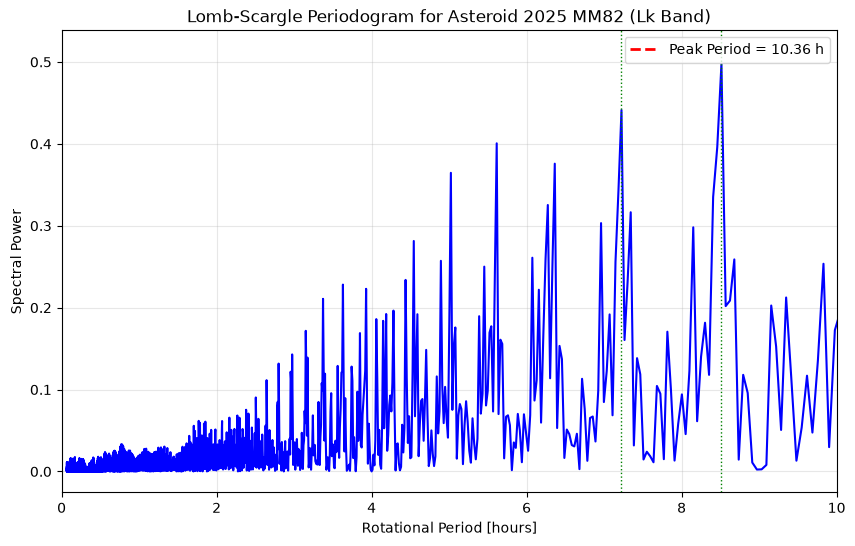

In [100]:
band = ['Lk', 'Lk']
# band = ['Lg', 'g']
df_band = df_obj_comp[(df_obj_comp['band'] == band[0]) | (df_obj_comp['band'] == band[1])].copy()
t_band = df_band['t_days'].values
y_band = df_band['mag'].values
dy_band = df_band['rmsmag'].fillna(0.01).values

# Frequency grid: 1.0 to 10.0 cycles/day (corresponding to periods from 2.4 to 24 hours)
periods = [2/60, 24] # in hours
freq_grid = np.linspace(24/periods[1], 24/periods[0], 20000)
ls_band = LombScargle(t_band, y_band, dy_band)
power = ls_band.power(freq_grid)

main_peak_power = np.max(power)
best_freq = freq_grid[np.argmax(power)]
best_phot_period = 24.0 / best_freq
best_rot_period = 2.0 * best_phot_period  # Double-peaked rotational period
print(f"Photometric period: {best_phot_period:.2f} hours")
print(f"Derived asteroid rotation period: {best_rot_period:.2f} hours")

# Find periodogram peaks
peaks, _ = find_peaks(power)
threshold = 0.8 * main_peak_power
high_power_indices = np.where(power >= threshold)[0]
high_power_peaks = np.intersect1d(peaks, high_power_indices)

print(f"\nAll periodogram peaks with >80% of main peak power:")

all_rot_periods = []
peak_data = []
for i, idx in enumerate(high_power_peaks):
    freq = freq_grid[idx]
    ph_per = 24.0 / freq
    rot_per = 2.0 * ph_per
    rel_pwr = power[idx] / main_peak_power
    all_rot_periods = np.append(all_rot_periods, rot_per)
    peak_data.append({
        "frequency": freq,
        "rotational_period_h": rot_per,
        "relative_power": rel_pwr
    })
    print(f"[{i}] Rotational Period = {rot_per:.2f} h | Power = {rel_pwr:.3f}")
df_peaks = pd.DataFrame(peak_data).sort_values(by='relative_power', ascending=False).reset_index(drop=True) 

fig, ax = plt.subplots(figsize=(10, 6))

period_grid_hours = (24.0 / freq_grid) * 2.0  # Converted to rotational period
ax.plot(period_grid_hours, power, color='b', lw=1.5)
ax.axvline(best_rot_period, color='r', linestyle='--', lw=2, label=f'Peak Period = {best_rot_period:.2f} h')
for period in all_rot_periods:
    ax.axvline(period, color='g', linestyle=':', alpha=1, lw=1)

ax.set_xlabel('Rotational Period [hours]')
ax.set_ylabel('Spectral Power')
ax.set_title(f'Lomb-Scargle Periodogram for Asteroid {provid} ({band[0]} Band)')
ax.set_xlim(0, 10)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)


Selected peak:

In [101]:
isel = 2
freq_sel = df_peaks.iloc[isel]['frequency']
per_sel = df_peaks.iloc[isel]['rotational_period_h']
rel_pwr = df_peaks.iloc[isel]['relative_power']
print(f"[{isel}] Rotational Period = {per_sel:.2f} h | Power = {rel_pwr:.3f}")


[2] Rotational Period = 8.51 h | Power = 0.970


Folded light-curve:

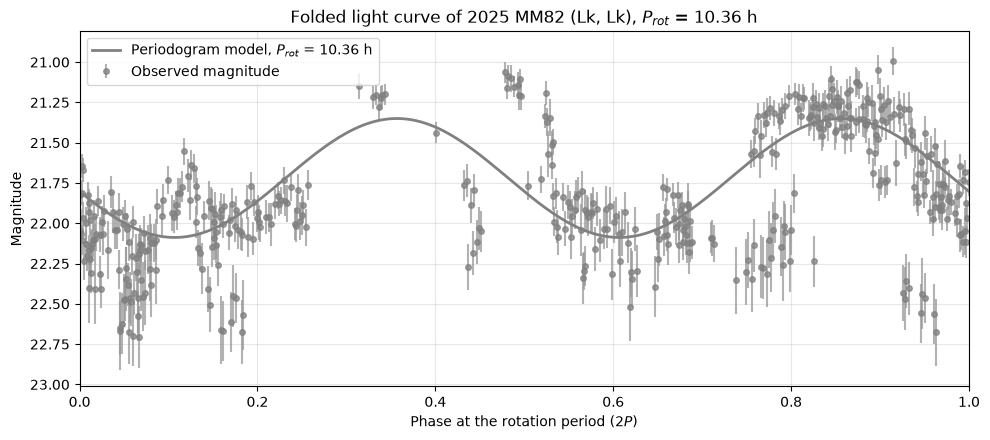

In [102]:
t0 = t_band.min()
phase = np.mod((t_band - t0) * freq_sel, 1.0)
phase_grid = np.linspace(0, 1, 400)
y_model = ls_band.model(t0 + phase_grid / freq_sel, freq_sel)

# Same model sampled across one rotation (two photometric cycles)
phase_rot = np.mod((t_band - t0) * freq_sel / 2.0, 1.0)
phase_rot_grid = np.linspace(0, 1, 400)
y_model_rot = ls_band.model(t0 + phase_rot_grid * 2.0 / freq_sel, freq_sel)

fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))

b = band if isinstance(band, str) else band[0]
curve_color = band_colors.get(b, 'k')
ax.errorbar(
    phase_rot, y_band, yerr=dy_band, fmt='o', ms=4, alpha=0.75,
    color=curve_color, ecolor='0.6', label='Observed magnitude'
)
ax.plot(
    phase_rot_grid, y_model_rot, color=curve_color, lw=2,
    label=f'Periodogram model, $P_{{rot}}$ = {best_rot_period:.2f} h'
)
ax.set_xlabel('Phase at the rotation period ($2P$)')
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', frameon=True)
ax.set_ylabel('Magnitude')
ax.set_title(f"Folded light curve of {provid} ({', '.join(band)}), $P_{{rot}}$ = {best_rot_period:.2f} h")
fig.tight_layout()
fig.savefig(fig_dir + f"phase_model_{provid.replace(' ', '_')}.png", dpi=300)

Now let's see the sine curve and the data:

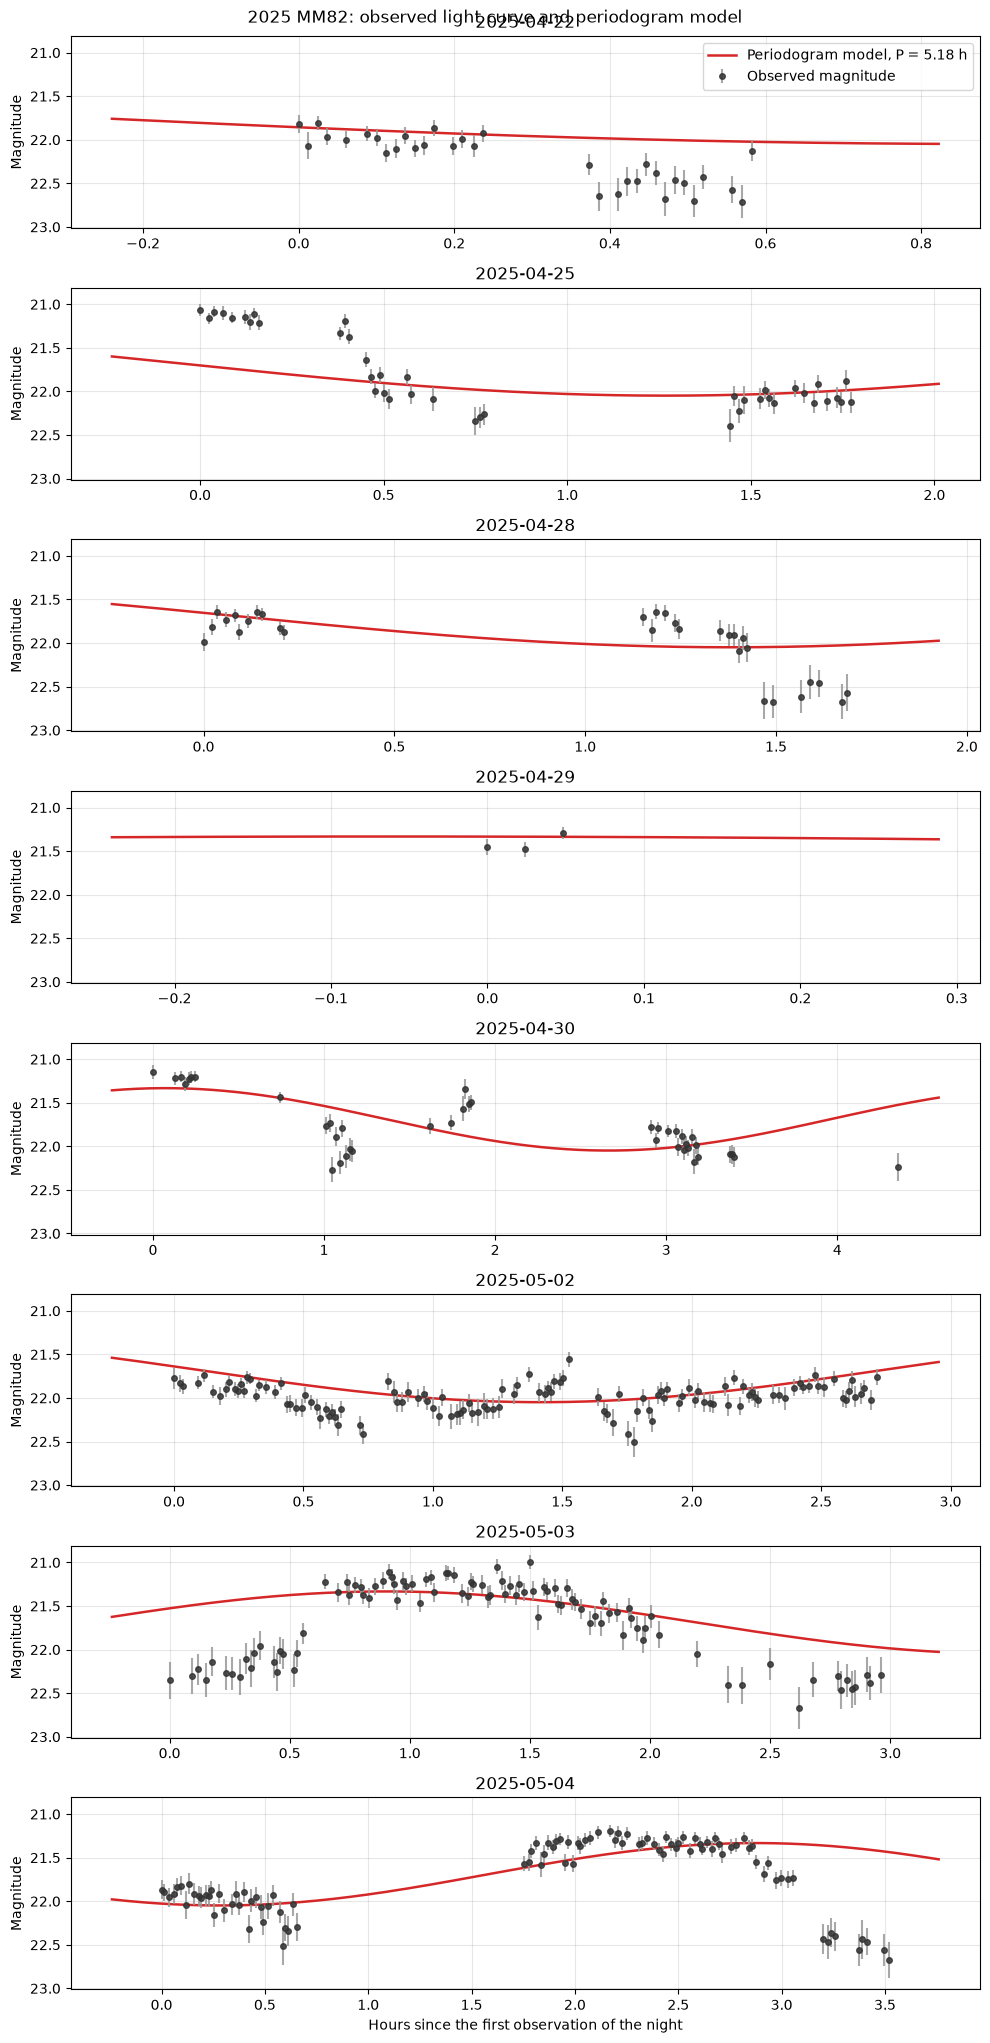

In [103]:
nights_band = df_band['night'].drop_duplicates().sort_values()
n_nights_band = len(nights_band)
fig, axs = plt.subplots(n_nights_band, 1, figsize=(10, 2.6 * n_nights_band), sharey=True)
if n_nights_band == 1:
    axs = [axs]

for ax, night in zip(axs, nights_band):
    sel = df_band['night'] == night
    t_night = df_band.loc[sel, 't_days'].to_numpy()
    y_night = df_band.loc[sel, 'mag'].to_numpy()
    dy_night = df_band.loc[sel, 'rmsmag'].fillna(0.01).to_numpy()
    t_left, t_right = t_night.min(), t_night.max()
    pad = max(0.01, 0.05 * (t_right - t_left))
    t_grid = np.linspace(t_left - pad, t_right + pad, 400)
    y_grid = ls_band.model(t_grid, best_freq)
    hours = (t_night - t_left) * 24.0
    hours_grid = (t_grid - t_left) * 24.0
    ax.errorbar(
        hours, y_night, yerr=dy_night, fmt='o', ms=4, alpha=0.85,
        color='0.2', ecolor='0.6', label='Observed magnitude', zorder=3
    )
    ax.plot(
        hours_grid, y_grid, color='C3', lw=1.8,
        label=f'Periodogram model, P = {best_phot_period:.2f} h', zorder=2
    )
    ax.set_title(pd.to_datetime(night).strftime('%Y-%m-%d'))
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)

axs[0].invert_yaxis()
axs[0].legend(loc='best', frameon=True)
axs[-1].set_xlabel('Hours since the first observation of the night')
fig.suptitle(f'{provid}: observed light curve and periodogram model')
fig.tight_layout()
fig.savefig(fig_dir + f'timemodel_{provid.replace(" ", "_")}.png', dpi=300)
